In [5]:
import glob
import pathlib
import re
from tqdm.notebook import tqdm

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

from astropy.io import fits
from astropy.time import Time

In [6]:
moxsi_data_dir = pathlib.Path('/data1/moxsi')

In [7]:
folders = ["csie_2026082*", "csie_2026083*", "csie_20260901*", "csie_20260902*", "csie_20260903*"]
paths = [f"/data1/moxsi/moxsi_images_from_tvac/{folder}/*.fits" for folder in folders]

files = glob.glob(paths[0])
for path in paths[1:]:
    files += glob.glob(path)
files.sort(key=lambda file: int(re.search(r"frame(\d+).bin.fits", file).group(1)))

In [8]:
len(files), files[0], files[-1]

(55208,
 '/data1/moxsi/moxsi_images_from_tvac/csie_20260820_postcoldsurvival/csie_image_20260820_130726_784615_frame85139.bin.fits',
 '/data1/moxsi/moxsi_images_from_tvac/csie_20260903_OP_cold_final/csie_image_20260903_224550_600960_frame141175.bin.fits')

In [4]:
det0temp_poly = np.poly1d([-9.270400e-16, 9.978400e-12, -4.346300e-08, 9.685700e-05, -1.339600e-01, 1.243100e+02])
det1temp_poly = np.poly1d([-9.390500e-16, 1.012500e-11, -4.417600e-08, 9.861100e-05, -1.362200e-01, 1.255500e+02])

fpgatemp_poly = np.poly1d([-9.390500e-16, 1.012500e-11, -4.417600e-08, 9.861100e-05, -1.362200e-01, 1.255500e+02])

thermadc_poly = np.poly1d([-8.242800e-16, 8.990900e-12, -4.055000e-08, 9.534600e-05, -1.430500e-01, 1.379100e+02])

In [5]:
def steinharthart(coeff, scale=False):
    def func(dn):
        r = dn / (4096 - dn)
        if scale:
            r *= 10000
        result = 1 / np.poly1d(coeff[::-1])(np.log(r)) - 273.15
        return result
    return func

In [6]:
det0temp_sh = steinharthart([1.1292E-03, 2.3411E-04, 0.0000E+00, 8.7755E-08], scale=True)
det1temp_sh = steinharthart([3.3540E-03, 2.5708E-04, 1.8939E-06, 1.8973E-07])
fpgatemp_sh = steinharthart([3.3540E-03, 2.5708E-04, 1.8939E-06, 1.8973E-07])
thermadc_sh = steinharthart([3.3540E-03, 3.0013E-04, 5.0852E-06, 2.1877E-07])

In [7]:
nfiles = len(files)

#data = np.empty((nfiles, 2000, 1504))
#subdata = np.empty((nfiles, 5, 4))
#cropdata = np.empty((nfiles, 4, 4))
hdu_time = np.empty(nfiles)
csie_time = np.empty(nfiles)
csie_frame_id = np.empty(nfiles)
exptime = np.empty(nfiles)
median = np.empty(nfiles)
det0temp_dn = np.empty(nfiles)
det1temp_dn = np.empty(nfiles)
thermadc_dn = np.empty(nfiles)
fpgatemp_dn = np.empty(nfiles)

for i, file in enumerate(tqdm(files)):
    with fits.open(file) as f:
        hdu_time[i] = (Time(f[0].header["date"]) - Time('2026-08-20 01:59')).to('s').value
        csie_time[i] = f[0].header["SHCOARSE"] + f[0].header["SHFINE"] / 1000
        csie_frame_id[i] = f[0].header["frame_id"]
        exptime[i] = f[0].header["exptime"]
        
        #data[i, :, :] = f[0].data
        #subdata[i, :, :] = f[0].data[200::400, 188::376]
        #cropdata[i, :, :] = f[0].data[200:204, 188:192]
        median[i] = np.median(f[0].data[:, -376:])  # fourth stripe
        det0temp_dn[i] = f[0].header["det0temp"]
        det1temp_dn[i] = f[0].header["det1temp"]
        fpgatemp_dn[i] = f[0].header["fpgatemp"]
        thermadc_dn[i] = f[0].header["thermadc"]

  0%|          | 0/55208 [00:00<?, ?it/s]

In [8]:
det0temp = det0temp_sh(det0temp_dn)
det1temp = det1temp_sh(det1temp_dn)
fpgatemp = fpgatemp_sh(fpgatemp_dn)
thermadc = thermadc_sh(thermadc_dn)

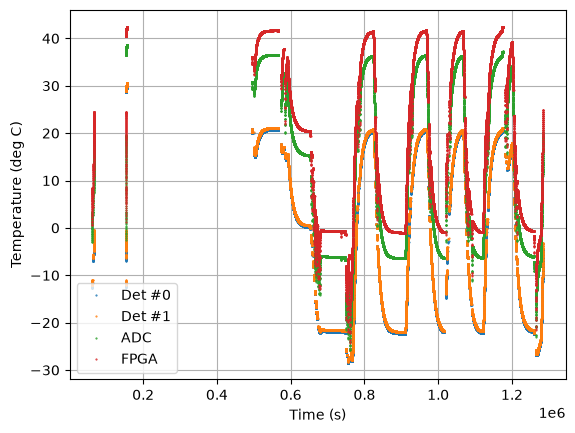

In [9]:
fig = plt.figure()
ax = fig.add_subplot()

ax.plot(hdu_time, det0temp, '.', markersize=1, label='Det #0')
ax.plot(hdu_time, det1temp, '.', markersize=1, label='Det #1')

ax.plot(hdu_time, thermadc, '.', markersize=1, label='ADC')
ax.plot(hdu_time, fpgatemp, '.', markersize=1, label='FPGA')

ax.grid()
ax.set_xlabel("Time (s)")
ax.set_ylabel("Temperature (deg C)")
ax.legend()

plt.show()

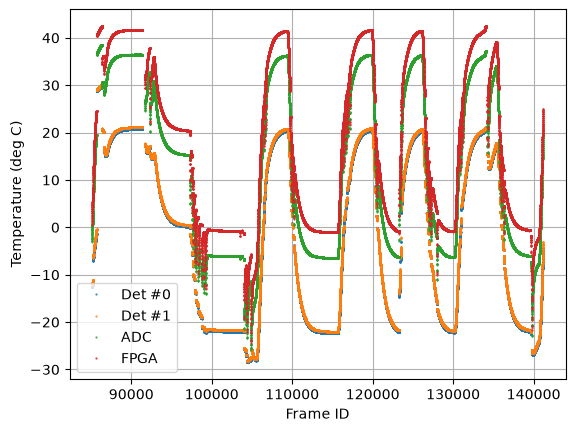

In [10]:
fig = plt.figure()
ax = fig.add_subplot()

ax.plot(csie_frame_id, det0temp, '.', markersize=1, label='Det #0')
ax.plot(csie_frame_id, det1temp, '.', markersize=1, label='Det #1')

ax.plot(csie_frame_id, thermadc, '.', markersize=1, label='ADC')
ax.plot(csie_frame_id, fpgatemp, '.', markersize=1, label='FPGA')

ax.grid()
ax.set_xlabel("Frame ID")
ax.set_ylabel("Temperature (deg C)")
ax.legend()

plt.show()

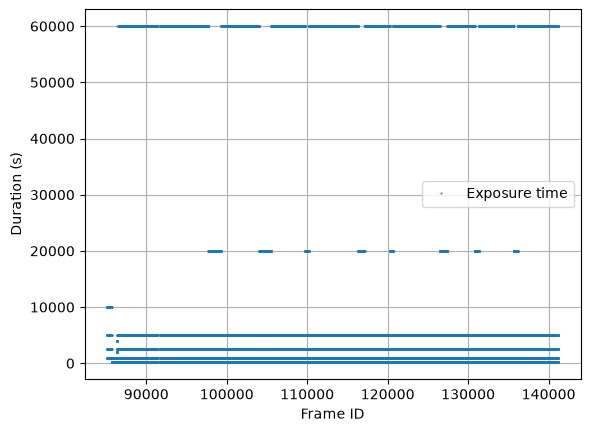

In [11]:
fig = plt.figure()
ax = fig.add_subplot()

ax.plot(csie_frame_id, exptime, '.', markersize=1, label='Exposure time')

ax.grid()
ax.set_xlabel("Frame ID")
ax.set_ylabel("Duration (s)")
ax.legend()

plt.show()

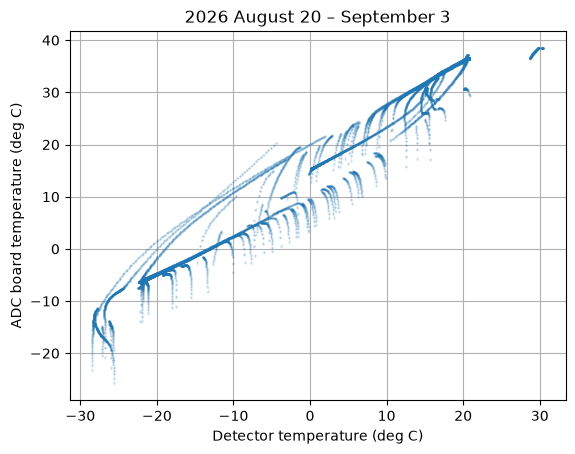

In [12]:
fig = plt.figure()
ax = fig.add_subplot()

ax.plot(det0temp, thermadc, '.', markersize=1, alpha=0.1)

ax.grid()
ax.set_xlabel("Detector temperature (deg C)")
ax.set_ylabel("ADC board temperature (deg C)")
ax.set_title("2026 August 20 – September 3")

plt.show()

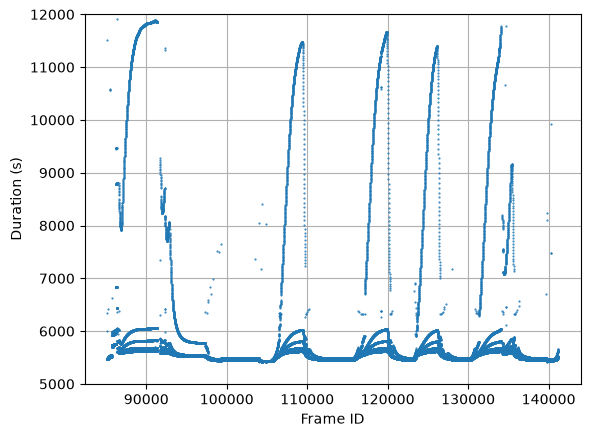

In [72]:
fig = plt.figure()
ax = fig.add_subplot()

ax.plot(csie_frame_id, median, '.', markersize=1)

ax.grid()
ax.set_xlabel("Frame ID")
ax.set_ylabel("Duration (s)")

ax.set_ylim(5000, 12000)

plt.show()

In [183]:
# Frames that are not overexposed and do not obviously have the LED on
good = ((exptime <= 10000) & (median < 6200)) | ((exptime > 10000) & (median < 12000))

# Good frames that are no more than 5-s exposures and are preceded by a good frame
clean = (exptime <= 5000) & (csie_frame_id >= 86392) & (csie_time > np.roll(csie_time, 1)) & good & np.roll(good, 1)

In [184]:
u1000 = exptime == 1000
u2500 = exptime == 2500
u5000 = exptime == 5000
u0200 = exptime == 200

u10000 = exptime == 10000
u60000 = exptime == 60000

In [185]:
def model(X, a, b, c, d, e, f):
    t_det0, t_adc, exposure = X
#    return a + b * np.exp(t_det0 / c) + d * t_det0 + e * t_adc
#    return a + b * exposure * np.exp(t_det0 / c) + d * t_det0 + e * t_adc
#    return a + b * (exposure + f) * np.exp(t_det0 / c) + d * t_det0 + e * t_adc
    return a + b * exposure * np.exp(t_det0 / c) + d * t_det0 + e * t_det0**2 + f * t_adc
#    return a + b * exposure * np.exp(t_det0 / c) + d * t_det0 + e * t_det0**2 + 2 * t_adc
#    return a + b * exposure * np.exp(t_det0 / c) + d * t_det0 + e * t_det0**2 + f * t_adc + g*t_adc**2
#    return a + b * np.exp(t_det0 / c) + d * exposure * np.exp(t_det0 / e) + f * t_det0 + g * t_adc
#    return a + b * t_det0 + c * t_det0**2 + d * t_det0**3 + e * t_adc
#    return a + b * np.exp(t_det0 / c) + d * (t_adc - t_det0)

In [186]:
space3d = np.vstack((det0temp, thermadc, exptime))

In [187]:
#popt, pcov, infodict, mesg, ier = curve_fit(model, space3d[:, u1000], median[u1000], full_output=True)
#popt, pcov, infodict, mesg, ier = curve_fit(model, space3d[:, u2500], median[u2500], full_output=True)
#popt, pcov, infodict, mesg, ier = curve_fit(model, space3d[:, u5000], median[u5000], full_output=True)

popt, pcov, infodict, mesg, ier = curve_fit(model, space3d[:, clean], median[clean], full_output=True)

In [188]:
popt, pcov, infodict, mesg, ier

(array([5.50733010e+03, 3.94343750e-03, 6.62723530e+00, 2.66865505e+00,
        1.72370291e-02, 7.95703106e-01]),
 array([[ 1.21753706e-02, -1.57882408e-07, -8.99963917e-05,
          7.34964847e-04, -2.00311964e-06, -7.31092966e-04],
        [-1.57882408e-07,  4.90947808e-11,  2.73475085e-08,
         -1.93749460e-09,  2.46346984e-10,  6.47158632e-10],
        [-8.99963917e-05,  2.73475085e-08,  1.55139529e-05,
         -6.47172512e-07,  1.62596121e-07,  4.42541023e-07],
        [ 7.34964847e-04, -1.93749460e-09, -6.47172512e-07,
          5.49297750e-05,  2.18721802e-07, -5.19315317e-05],
        [-2.00311964e-06,  2.46346984e-10,  1.62596121e-07,
          2.18721802e-07,  1.41040287e-08, -1.34622265e-07],
        [-7.31092966e-04,  6.47158632e-10,  4.42541023e-07,
         -5.19315317e-05, -1.34622265e-07,  5.11187241e-05]]),
 {'fvec': array([ 3.42407913,  3.42407913, -1.00905131, ...,  3.04259447,
          2.10708728, -0.65908813], shape=(42987,)),
  'nfev': 389,
  'fjac': array(

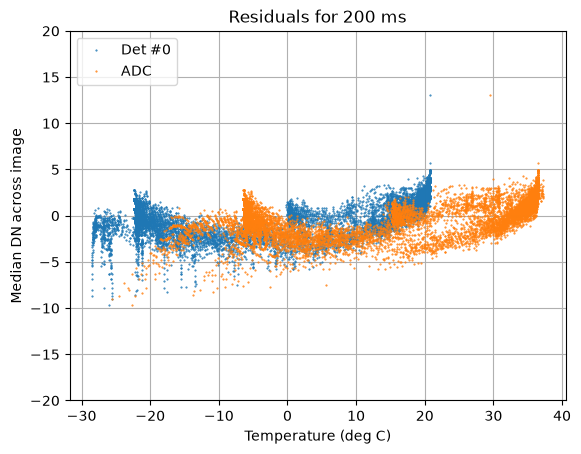

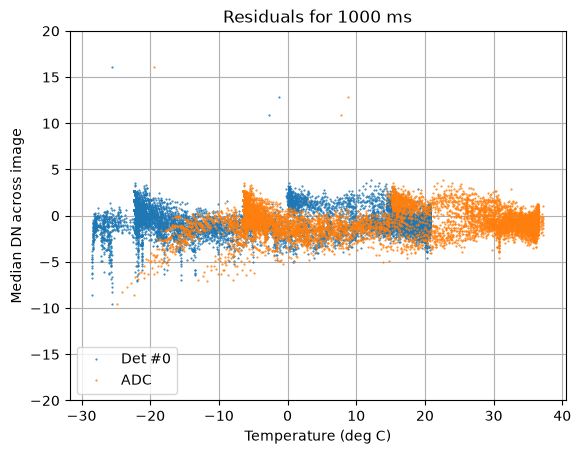

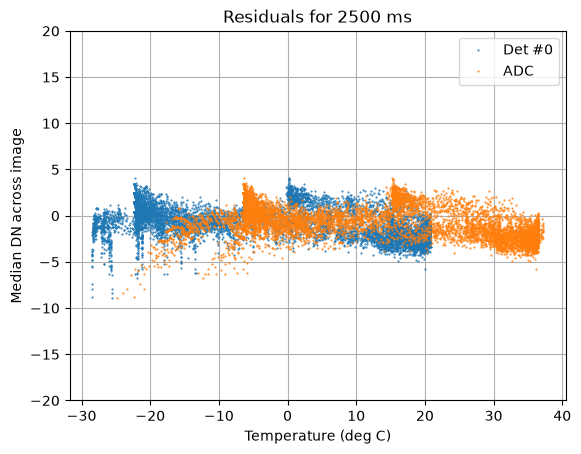

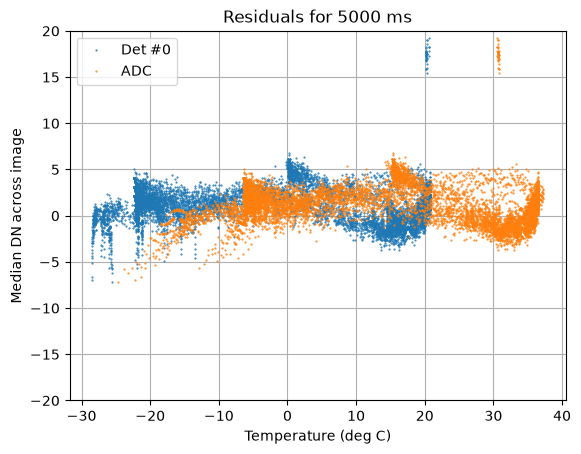

In [191]:
for duration in [200, 1000, 2500, 5000]:
    use = (exptime == duration) & clean

    fig = plt.figure()
    ax = fig.add_subplot()
    
    ax.plot(det0temp[use], median[use] - model(space3d[:, use], *popt), '.', markersize=1, label='Det #0')
    ax.plot(thermadc[use], median[use] - model(space3d[:, use], *popt), '.', markersize=1, label='ADC')
    
    ax.grid()
    ax.set_ylim(-20, 20)
    
    ax.set_title(f'Residuals for {duration} ms')
    ax.set_xlabel("Temperature (deg C)")
    ax.set_ylabel("Median DN across image")
    ax.legend()

plt.show()

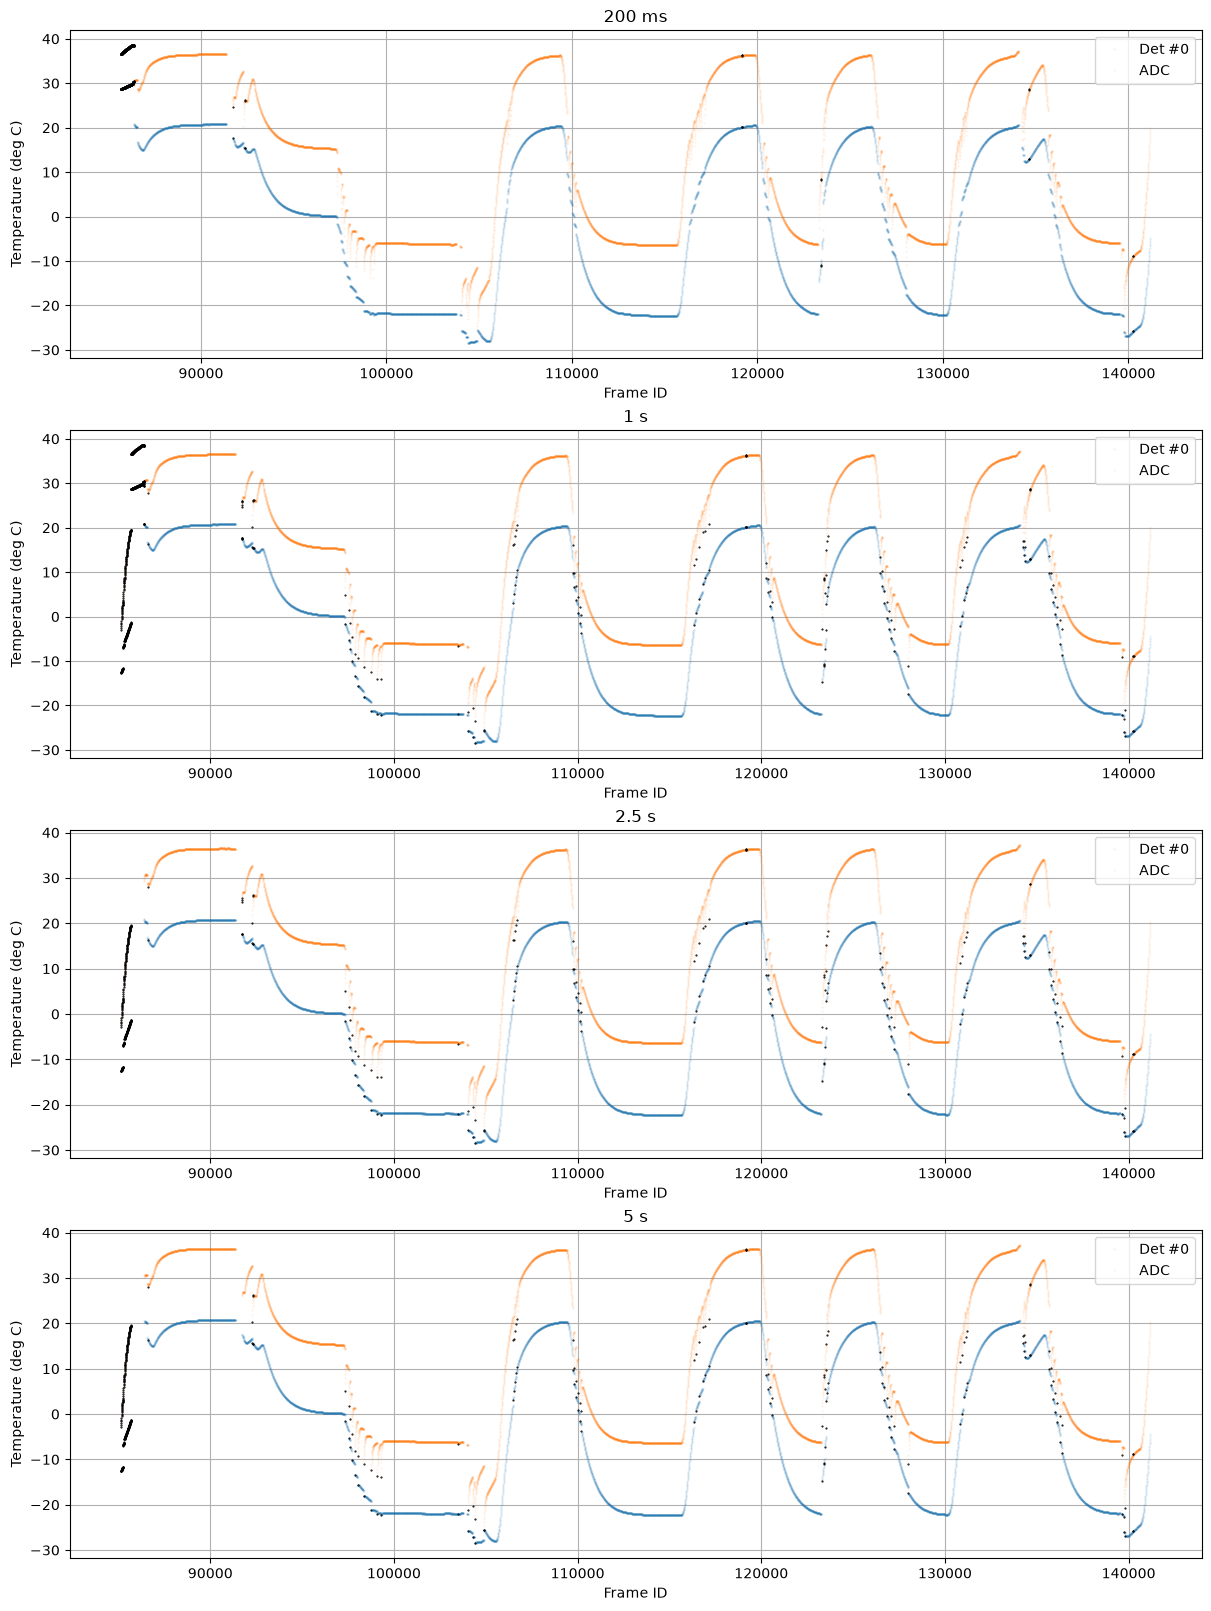

In [192]:
fig, axs = plt.subplots(4, 1, figsize=(12, 16), layout="constrained")

for ax, use, title in zip(axs, [u0200, u1000, u2500, u5000], ["200 ms", "1 s", "2.5 s", "5 s"]):
    ax.plot(csie_frame_id[use], det0temp[use], '.', markersize=1, alpha=0.1, label='Det #0')
    ax.plot(csie_frame_id[use], thermadc[use], '.', markersize=1, alpha=0.1, label='ADC')

    ax.plot(csie_frame_id[use & ~clean], det0temp[use & ~clean], '.', markersize=1, color='k')
    ax.plot(csie_frame_id[use & ~clean], thermadc[use & ~clean], '.', markersize=1, color='k')

    ax.grid()
    ax.set_title(title)
    ax.set_xlabel("Frame ID")
    ax.set_ylabel("Temperature (deg C)")
    ax.legend()

plt.show()

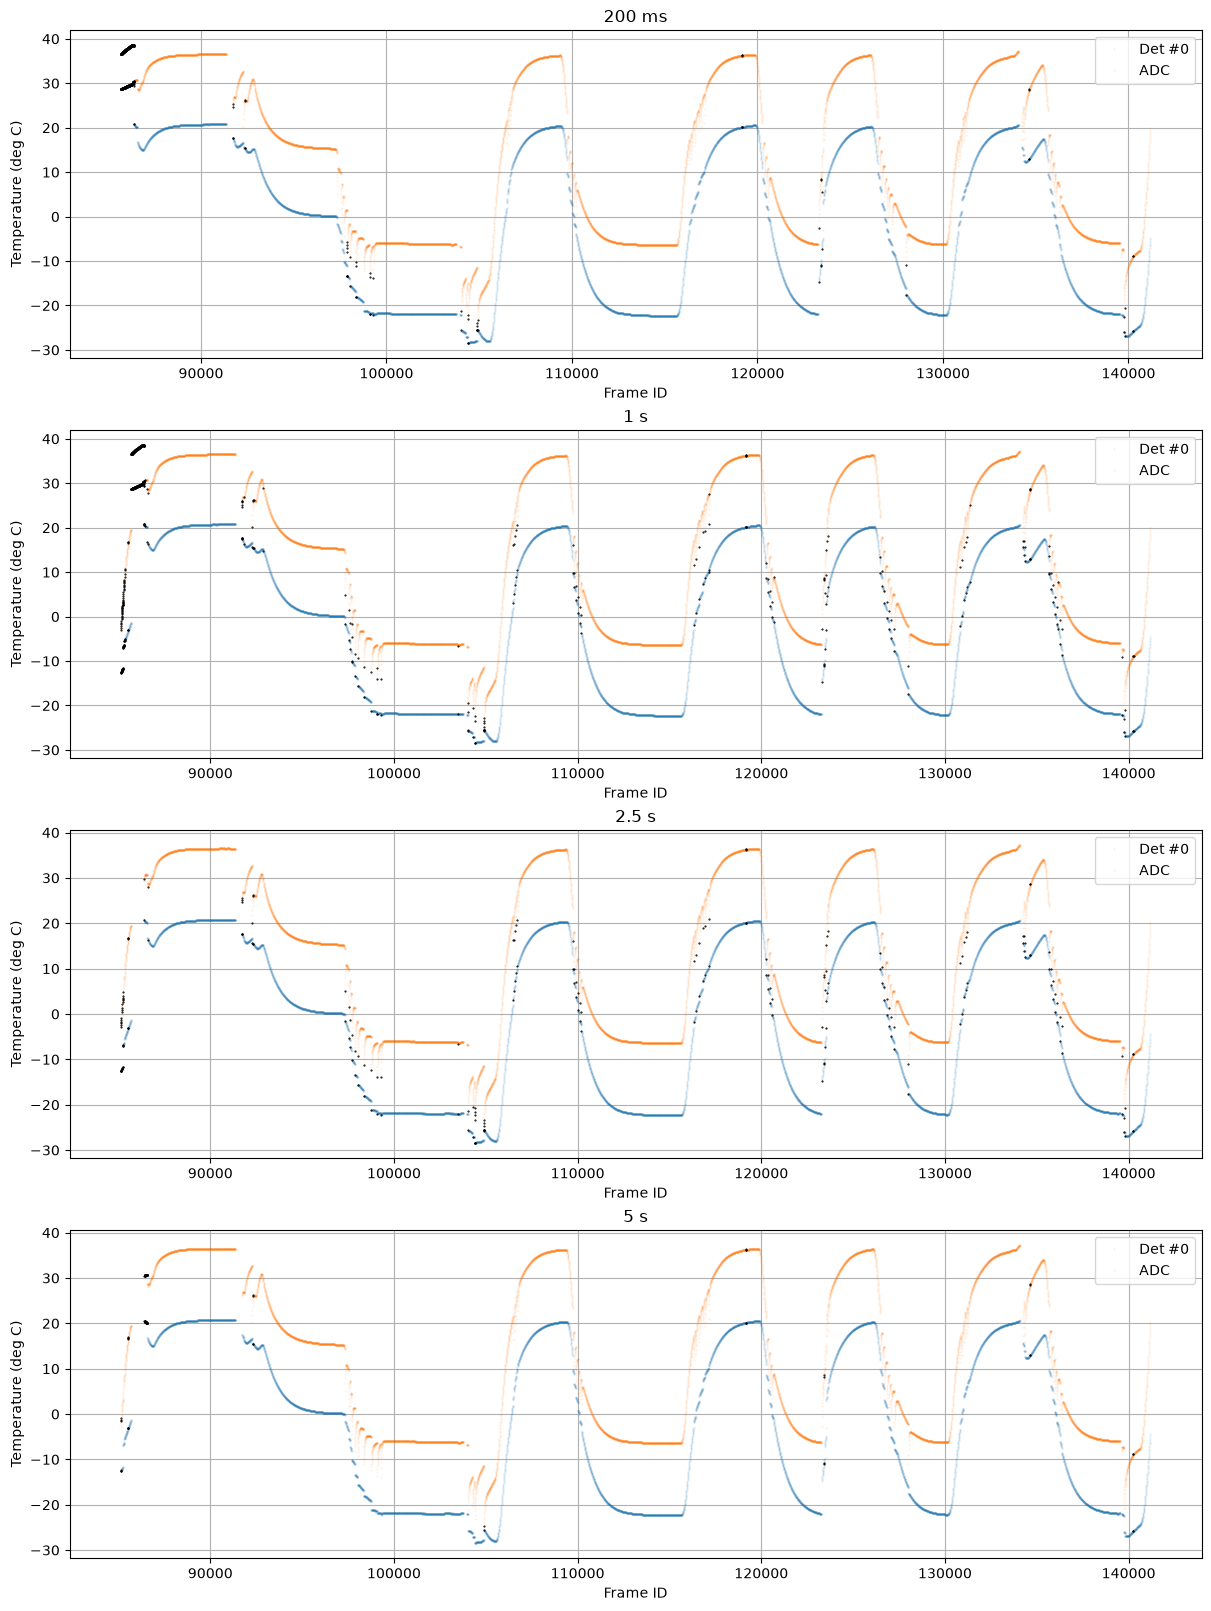

In [197]:
delta = median - model(space3d, *popt)
tol = np.abs(delta) < 7

fig, axs = plt.subplots(4, 1, figsize=(12, 16), layout="constrained")

for ax, use, title in zip(axs, [u0200, u1000, u2500, u5000], ["200 ms", "1 s", "2.5 s", "5 s"]):
    ax.plot(csie_frame_id[use], det0temp[use], '.', markersize=1, alpha=0.1, label='Det #0')
    ax.plot(csie_frame_id[use], thermadc[use], '.', markersize=1, alpha=0.1, label='ADC')

    ax.plot(csie_frame_id[use & ~tol], det0temp[use & ~tol], '.', markersize=1, color='k')
    ax.plot(csie_frame_id[use & ~tol], thermadc[use & ~tol], '.', markersize=1, color='k')

    ax.grid()
    ax.set_title(title)
    ax.set_xlabel("Frame ID")
    ax.set_ylabel("Temperature (deg C)")
    ax.legend()

plt.show()

In [194]:
print(np.sum(clean), len(clean))

42987 55208


In [195]:
with open('clean_TVAC_images.txt', 'w') as f:
    for item in np.array(files)[clean]:
        f.write(f'{item}\n')